# Bài tập về nhà: Đo lường và giám sát chất lượng dữ liệu

**Môn:** DS317, Chương 4: Chất lượng dữ liệu

**Nhiệm vụ theo đề bài:**

1. Lập từ điển dữ liệu và quy tắc kiểm tra.
2. Tính sáu khía cạnh ở mức hạt, gồm completeness, validity, uniqueness, consistency, accuracy và timeliness.
3. Trực quan hoá theo thời gian.
4. Áp dụng ít nhất một phương pháp cải thiện và so sánh trước với sau.

**Dữ liệu:** Freddie Mac Single-Family Loan-Level Dataset (SFLLD), bản Release 47 (7/2026), gồm 25 quý
từ 2020Q1 đến 2026Q1. Mỗi quý có file gốc `orig_*.txt` (31 cột) và file hiệu suất `perf_*.txt` (35 cột),
phân tách bằng dấu `|` và không có dòng tiêu đề. Tổng dung lượng khoảng 59 GB, file perf lớn nhất khoảng 7,5 GB.

Bộ dữ liệu được tải trực tiếp từ Freddie Mac. Tên cột trong từ điển đối chiếu với `file_layout.xlsx` và
`General User Guide` chính thức, không dùng suy đoán. So với layout 32 cột, Release 47 thay đổi hai file:

- File orig bỏ `MI Cancellation Indicator` và `Servicer Name`, thêm `VantageScore 4.0` ở vị trí 31, nên
  các vị trí 25 đến 31 dịch lên một bậc.
- File perf thêm `MI Cancellation Indicator`, `Servicer Name` (chuyển từ orig) và `Bankruptcy Cramdown
  Costs` ở các vị trí 33, 34 và 35.

**Ràng buộc hạ tầng,** đã xử lý trong `scripts/dq_core.py`:

- Máy có 15 GB RAM, còn trống khoảng 4 đến 6 GB, nên chốt `memory_limit='3GB'`.
- `/tmp` là tmpfs chạy trên RAM, nên không dùng làm thư mục tạm của DuckDB mà dùng `.duckdb_tmp/` trên đĩa.
- Mọi phép đo chạy bằng SQL aggregate trực tiếp trên file qua DuckDB, không materialize 70 triệu dòng.
- Kết quả được cache theo quý trong `output/cache/`, nhờ đó chạy lại được sau gián đoạn.


## Khung lý thuyết và độ đo (Chương 4)

Chất lượng dữ liệu là mức độ phù hợp của dữ liệu với mục đích sử dụng (fitness for use), một khái niệm
đa khía cạnh: không có một con số duy nhất mà là một vectơ các độ đo. Nguyên tắc đo là đo ở mức hạt dữ liệu,
từ từng giá trị đến thuộc tính, bản ghi, bảng và toàn bộ cơ sở dữ liệu, rồi tổng hợp lên các mức cao hơn.
Bài này đo ở mức hạt rồi tổng hợp theo quý.

Sáu khía cạnh cốt lõi theo DAMA UK (2013) và UK Government (2020). Mỗi khía cạnh tương ứng một câu hỏi:

| Khía cạnh | Câu hỏi mà nó trả lời |
|---|---|
| **Completeness** | Dữ liệu đã đủ chưa, mọi giá trị bắt buộc có mặt? |
| **Validity** | Giá trị có nằm trong định dạng và miền cho phép (range, domain, regex)? |
| **Uniqueness** | Mỗi thực thể có xuất hiện đúng một lần, khoá có trùng? |
| **Consistency** | Dữ liệu có đồng bộ giữa các bảng và hệ thống, ràng buộc liên kết có thoả? |
| **Accuracy** | Dữ liệu có phản ánh đúng thực tế khi đối chiếu nguồn tin cậy? |
| **Timeliness** | Dữ liệu có được cập nhật kịp thời so với thời điểm sử dụng? |

ISO/IEC 25012 chuẩn hoá 15 đặc tính chất lượng dữ liệu theo hai góc nhìn. Năm đặc tính inherent thuộc riêng
phần dữ liệu gồm accuracy, completeness, consistency, credibility và currentness. Ba đặc tính
system-dependent phụ thuộc hệ thống lưu trữ và truy xuất gồm availability, portability và recoverability.
Bảy đặc tính còn lại dùng chung cho cả hai góc nhìn gồm accessibility, compliance, confidentiality,
efficiency, precision, traceability và understandability. Hướng dẫn đo lường định lượng cho các đặc tính
này nằm trong ISO/IEC 25024.

Tập khía cạnh chuẩn chưa có đồng thuận tuyệt đối (Sebastian-Coleman, 2012). Tổng quan tài liệu cho thấy
bốn khía cạnh phổ biến nhất là completeness, validity, consistency và accuracy (Ehrlinger & Wöß, 2022).
Bài này đo cả sáu khía cạnh vì bộ dữ liệu cho phép đo được đủ cả sáu.

Chương 4 nêu ba dạng hàm độ đo khách quan, và bài này dùng đủ cả ba:

1. Tỷ số đơn giản `1 - số_lỗi / tổng_số`, dùng cho completeness, validity, uniqueness và consistency,
   chẳng hạn completeness bằng `1 - null_cells / (rows × ncols)`.
2. Tổng hợp kiểu min/max theo hướng bảo thủ, tức điểm tổng thể lấy theo điểm thành phần yếu nhất, dùng cho
   proxy sức khoẻ `Ssan+ = min(completeness, validity)` ở mục mặt phẳng chẩn đoán. Cùng tinh thần đó, một
   bản ghi chỉ được coi là thoả validity khi mọi quy tắc đều thoả.
3. Trung bình có trọng số với tổng trọng số bằng 1, dùng khi tổng hợp 25 quý thành chỉ số tổng thể ở mục 4,
   với trọng số là số bản ghi `n_rows` của từng quý.

Quy tắc 1-10-100 (Labovitz & Chang, 1992) cho rằng chi phí phòng ngừa lỗi trước khi nhập là \$1, chi phí
sửa sau khi đã nhập là \$10, và chi phí để lỗi lan vào vận hành là \$100. Các quy tắc kiểm tra ngay lúc
ingest ở mục 1 chính là kiểm soát shift-left ở mức \$1.

TEMPO-DQ (nguồn chính: Nguyen, T., Nguyen, H.-T., & Nguyen-Hoang, T.-A. (2027). TEMPO-DQ framework.
*Information Processing & Management*, 64, 105175) với chuẩn đoán ba mức AccTEMPO M1, M2 và M3 là hướng mở
rộng của chương. Bài này thực hiện đủ sáu khía cạnh truyền thống, còn AccTEMPO được chương xếp vào phần
khuyến khích bổ sung chứ không bắt buộc.

Ranh giới phạm vi: Sperf và Ssan+ đúng nghĩa của AccTEMPO đòi hỏi confusion matrix hoặc probability matrix
từ một mô hình học máy. Bài này chỉ đo chất lượng dữ liệu, nên ở mục mặt phẳng chẩn đoán dùng proxy minh
bạch bằng công thức đóng, không huấn luyện mô hình chỉ để đặt tên vùng.


## 0. Thiết lập môi trường

Nạp module lõi `scripts/dq_core.py`, nơi chứa định nghĩa các độ đo và phần kết nối DuckDB an toàn bộ nhớ.


In [1]:
import sys, time
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import dq_core as dq

OUT = ROOT / "output"
for _d in (OUT, dq.OUT_DATA, dq.OUT_FIG):
    _d.mkdir(parents=True, exist_ok=True)
print("ROOT       :", ROOT)
print("TMP dir    :", dq.TMP_DIR, "(trên đĩa, không phải tmpfs)")
print("Số quý     :", len(dq.QUARTERS), dq.QUARTERS[0], "→", dq.QUARTERS[-1])
print("orig/perf  :", len(dq.ORIG_COLUMNS), "/", len(dq.PERF_COLUMNS), "cột")


ROOT       : /home/huynnz/GetAJob/DataMine
TMP dir    : /home/huynnz/GetAJob/DataMine/.duckdb_tmp (trên đĩa, không phải tmpfs)
Số quý     : 25 2020Q1 → 2026Q1
orig/perf  : 31 / 35 cột


## 1. Từ điển dữ liệu và quy tắc kiểm tra

Từ điển gồm 66 dòng, trong đó 31 dòng cho file orig và 35 dòng cho file perf. Mỗi dòng ghi vị trí, kiểu dữ
liệu, mức hạt (loan hoặc loan-month), mô tả, quy tắc kiểm tra máy kiểm được (range, domain, regex, non-null)
và ngưỡng đạt.

Tên cột lấy trực tiếp từ `file_layout.xlsx` của Freddie Mac, bản Release 47. `Servicer Name` nằm ở file perf,
vị trí 34. Vị trí 31 của file orig là `VantageScore 4.0`, với `9999` nghĩa là Not Available. File perf có
`MI Cancellation Indicator` ở vị trí 33 và `Bankruptcy Cramdown Costs` ở vị trí 35. Các miền giá trị theo
đúng General User Guide. Trạng thái quá hạn nhận `00..99`, `RA` hoặc `XX`. Zero-balance code nhận
`1..998`. Cả `999` và `9999` đều nghĩa là Not Available.


In [2]:
dd = pd.DataFrame(dq.DICT_ROWS, columns=['file','column','position','dtype',
                                        'grain','description_vi','rule','threshold'])
dd_path = dq.OUT_DATA / 'dq_data_dictionary.csv'
dd.to_csv(dd_path, index=False)
print(f"Đã lưu {dd_path} — {len(dd)} dòng "
      f"({(dd['file']=='orig').sum()} orig + {(dd['file']=='perf').sum()} perf)")
dd.head(12)


Đã lưu /home/huynnz/GetAJob/DataMine/output/data/dq_data_dictionary.csv — 66 dòng (31 orig + 35 perf)


,file,column,position,dtype,grain,description_vi,rule,threshold
0,orig,credit_score,0,int,loan,Điểm FICO của người vay,range:300-850,>= 0.95
1,orig,first_payment_date,1,YYYYMM,loan,Ngày trả nợ đầu tiên (năm+tháng),regex:^[0-9]{6}$ và tháng 01-12,>= 0.95
2,orig,first_time_homebuyer_flag,2,char,loan,Cờ mua nhà lần đầu,"domain:{Y,N}",>= 0.95
3,orig,maturity_date,3,YYYYMM,loan,Ngày đáo hạn (năm+tháng),regex:^[0-9]{6}$ và tháng 01-12,>= 0.95
4,orig,msa,4,code,loan,Mã vùng đô thị (MSA),regex:^[0-9]{5}$ hoặc rỗng,>= 0.95
5,orig,mi_percentage,5,int,loan,Tỷ lệ bảo hiểm thế chấp (%),range:0-55,>= 0.95
6,orig,number_of_units,6,int,loan,Số căn hộ,range:1-4,>= 0.95
7,orig,occupancy_status,7,char,loan,Tình trạng sử dụng nhà,"domain:{P,I,S}",>= 0.95
8,orig,cltv,8,int,loan,Tỷ lệ LTV cộng gộp (%),range:0-200,>= 0.95
9,orig,dti,9,int,loan,Tỷ lệ nợ trên thu nhập (%),range:0-65,>= 0.95


## 2. Sáu khía cạnh chất lượng dữ liệu ở mức hạt

Các độ đo được tính trên từng dòng, với hạt là loan cho file orig và loan-month cho file perf, sau đó lấy
trung bình theo quý.

| Khía cạnh | Công thức |
|---|---|
| **Completeness** | `1 - null_cells / (rows × ncols)` |
| **Validity** | trung bình tỷ lệ quy tắc miền giá trị thoả trên mỗi dòng, ô rỗng tính là N/A và được coi là đạt. Báo cáo hai cách đọc: cách chặt coi `XX` là vi phạm, cách theo spec coi `XX` là hợp lệ |
| **Uniqueness** | tỷ lệ dòng có khoá duy nhất, với orig là `loan_id` và perf là cặp `(loan_id, period)` |
| **Consistency** | tỷ lệ `loan_id` của perf xuất hiện trong orig cùng quý |
| **Accuracy** | tỷ lệ dòng thoả ràng buộc liên trường về UPB, lãi suất, mã kết thúc và thứ tự ngày |
| **Timeliness** | `max(0, 1 - lag_tháng / 12)` so với kỳ mới nhất 202603 |

Mọi độ đo đều chuẩn hoá về khoảng `[0,1]`. Ô chạy bên dưới dùng cache nếu đã có, vì lần chạy đầu mất khoảng
hai đến ba giờ cho cả 25 quý.


In [3]:
con = duckdb.connect()
con.execute(f"SET temp_directory='{dq.TMP_DIR}';")
con.execute("SET memory_limit='3GB';")
con.execute("SET preserve_insertion_order=false;")

df_m = dq.run_all_quarters(con)
m_path = dq.OUT_DATA / 'dq_metrics_by_quarter.csv'
df_m.to_csv(m_path, index=False)
print(f"\nĐã lưu {m_path} — {len(df_m)} dòng")
df_m.head(6)


  2020Q1: dùng cache (dq_metrics_2020Q1.csv)
  2020Q2: dùng cache (dq_metrics_2020Q2.csv)
  2020Q3: dùng cache (dq_metrics_2020Q3.csv)
  2020Q4: dùng cache (dq_metrics_2020Q4.csv)
  2021Q1: dùng cache (dq_metrics_2021Q1.csv)
  2021Q2: dùng cache (dq_metrics_2021Q2.csv)
  2021Q3: dùng cache (dq_metrics_2021Q3.csv)
  2021Q4: dùng cache (dq_metrics_2021Q4.csv)
  2022Q1: dùng cache (dq_metrics_2022Q1.csv)
  2022Q2: dùng cache (dq_metrics_2022Q2.csv)
  2022Q3: dùng cache (dq_metrics_2022Q3.csv)
  2022Q4: dùng cache (dq_metrics_2022Q4.csv)
  2023Q1: dùng cache (dq_metrics_2023Q1.csv)
  2023Q2: dùng cache (dq_metrics_2023Q2.csv)
  2023Q3: dùng cache (dq_metrics_2023Q3.csv)
  2023Q4: dùng cache (dq_metrics_2023Q4.csv)
  2024Q1: dùng cache (dq_metrics_2024Q1.csv)
  2024Q2: dùng cache (dq_metrics_2024Q2.csv)
  2024Q3: dùng cache (dq_metrics_2024Q3.csv)
  2024Q4: dùng cache (dq_metrics_2024Q4.csv)
  2025Q1: dùng cache (dq_metrics_2025Q1.csv)
  2025Q2: dùng cache (dq_metrics_2025Q2.csv)
  2025Q3: 

,quarter,source,completeness,validity,validity_spec,uniqueness,consistency,accuracy,timeliness,n_rows
0,2020Q1,orig,0.9345,1.0,1.0,1.0,1.0,1.0000,0.0000,517072
1,2020Q1,perf,0.3771,1.0,1.0,1.0,1.0,0.9963,0.0661,22186576
2,2020Q2,orig,0.9337,1.0,1.0,1.0,1.0,1.0000,0.0000,926253
3,2020Q2,perf,0.3751,1.0,1.0,1.0,1.0,0.9991,0.0763,46117163
4,2020Q3,orig,0.9340,1.0,1.0,1.0,1.0,1.0000,0.0000,1187782
5,2020Q3,perf,0.3747,1.0,1.0,1.0,1.0,0.9996,0.0845,64417206


### Kiểm tra tính hợp lệ của kết quả


In [4]:
DIMS = dq.DIMS
for d in DIMS:
    lo, hi = df_m[d].min(), df_m[d].max()
    assert 0 <= lo <= hi <= 1 + 1e-9, f"{d} ngoài [0,1]: [{lo}, {hi}]"
print("Mọi metric nằm trong [0,1]: OK")

# Bảng tổng hợp theo nguồn
summary = df_m.groupby('source')[DIMS].mean().round(4)
summary


Mọi metric nằm trong [0,1]: OK


,completeness,validity,uniqueness,consistency,accuracy,timeliness
source,,,,,,
orig,0.9350,1.0000,1.0,1.0,1.0000,0.1137
perf,0.3805,0.9639,1.0,1.0,0.9993,0.2771


## 3. Trực quan hoá theo thời gian

Lưới 2×3, mỗi ô là một khía cạnh chất lượng dữ liệu theo 25 quý. Mỗi khía cạnh được vẽ cho cả hai nguồn
orig và perf, kèm ngưỡng tham chiếu 0.95.


Đã lưu biểu đồ: /home/huynnz/GetAJob/DataMine/output/figures/dq_dimensions_timeseries.png


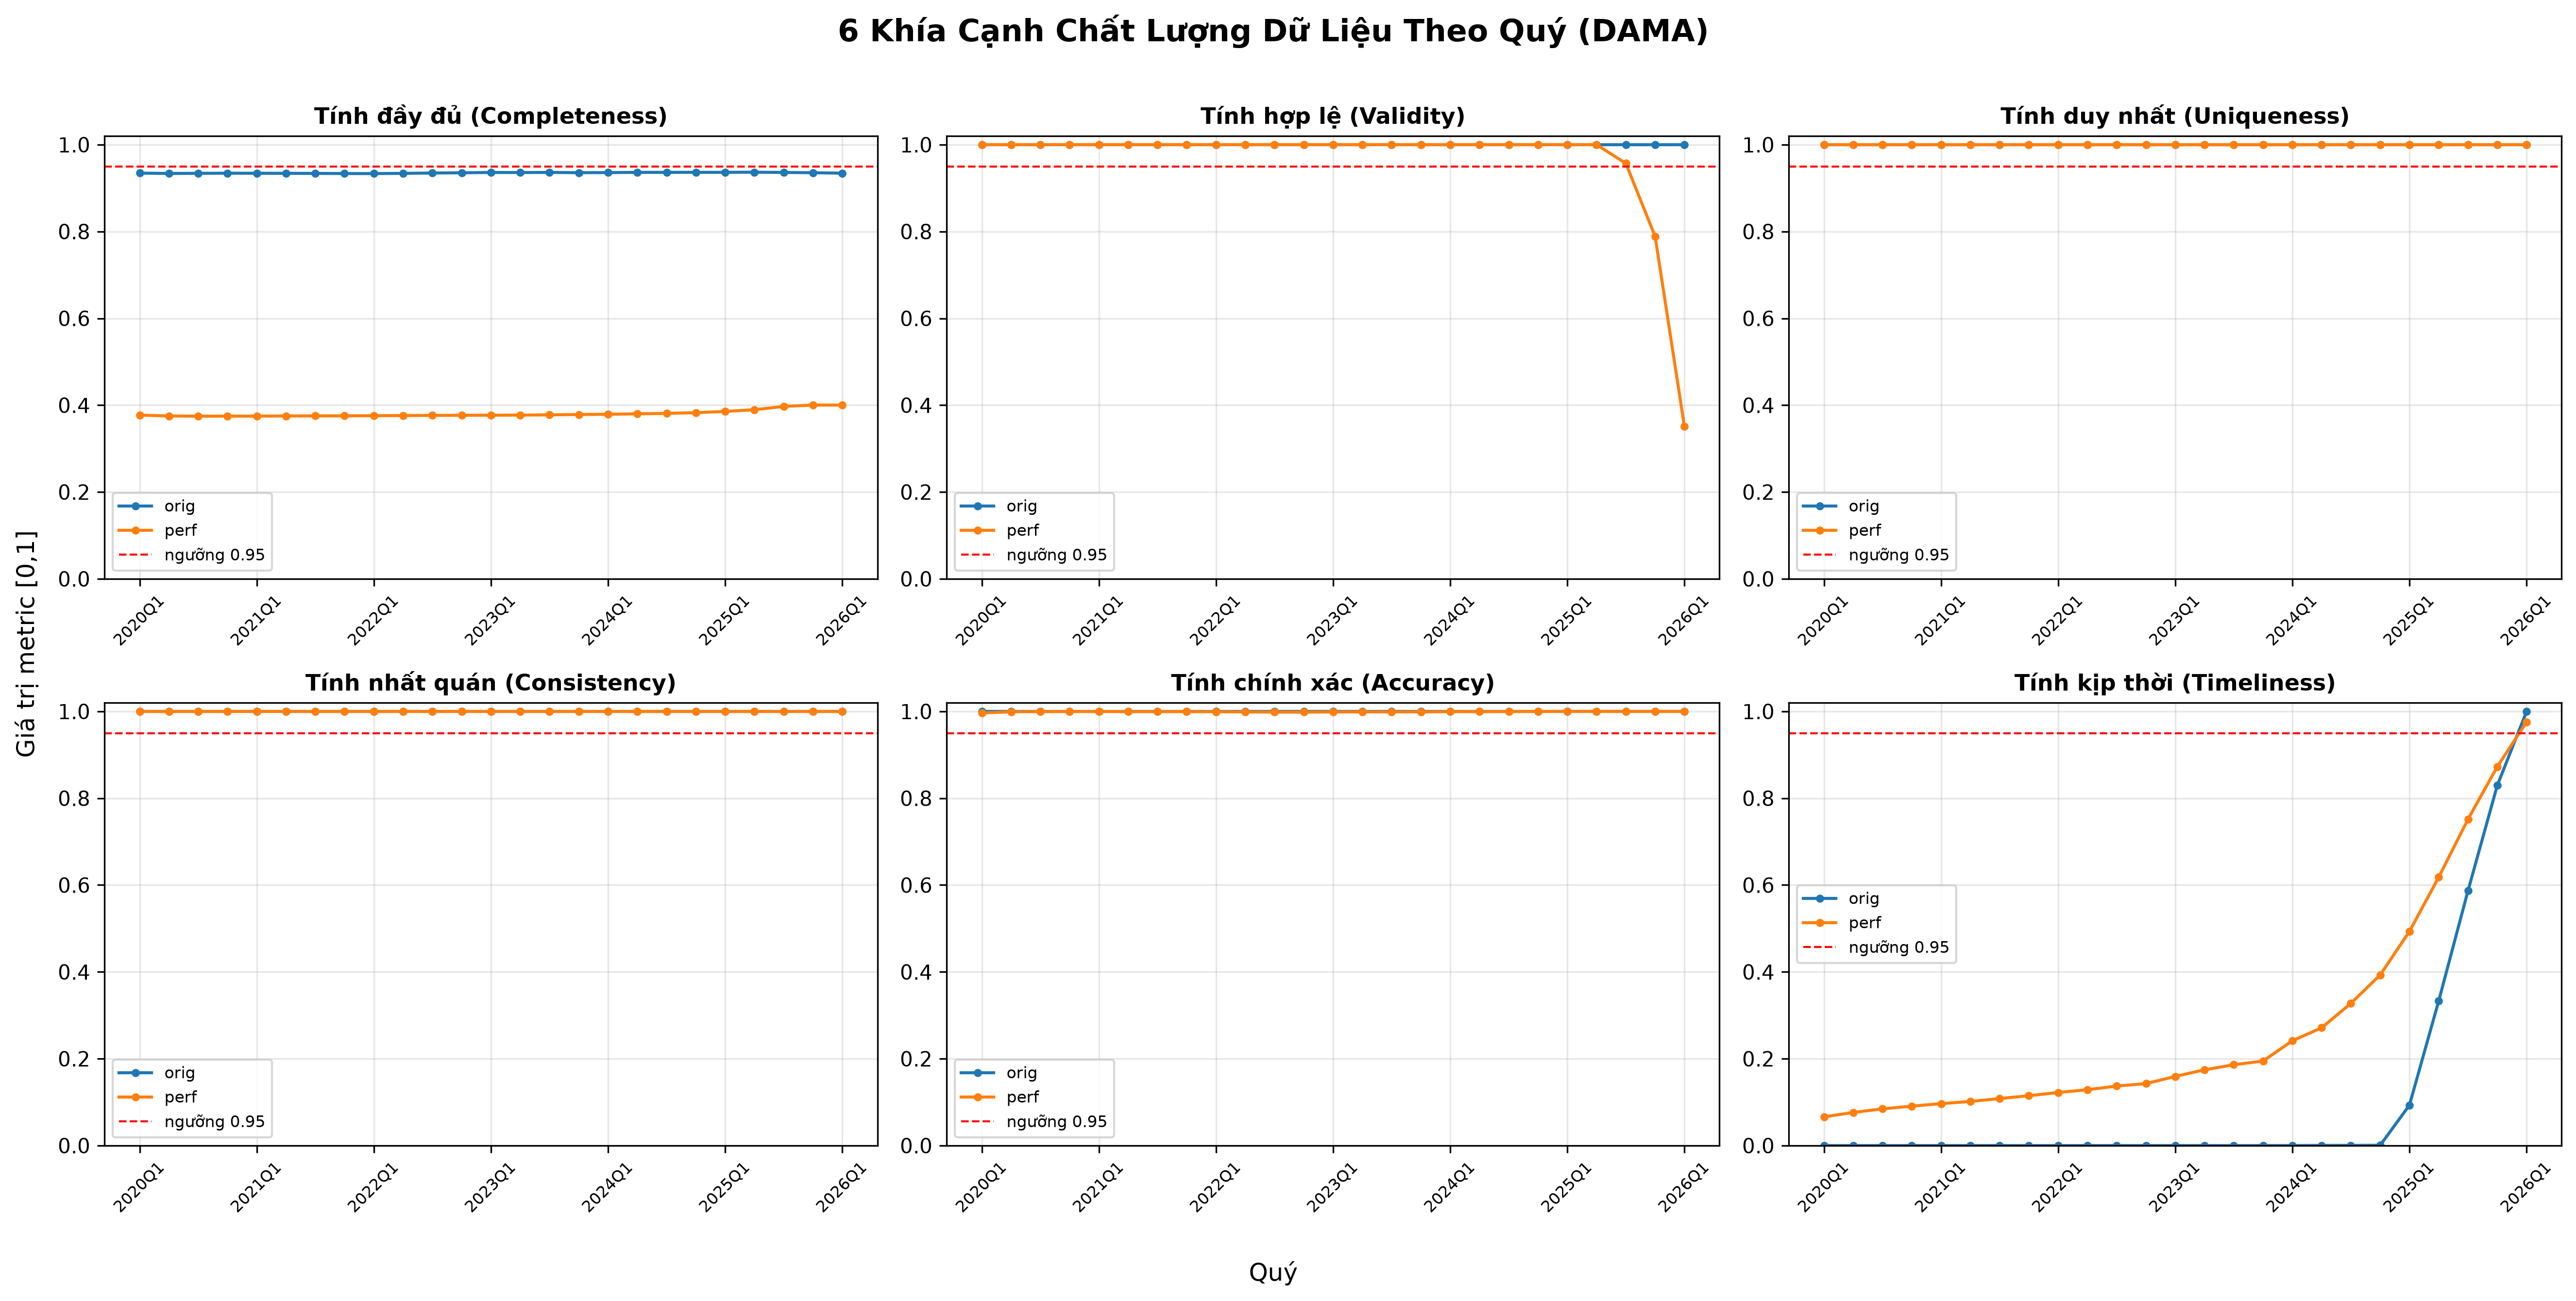

In [5]:
dq.plot_timeseries(df_m)
from IPython.display import Image, display
display(Image(filename=str(dq.OUT_FIG / 'dq_dimensions_timeseries.png')))


### Phát hiện bất thường: giá trị `XX` trong trạng thái quá hạn

Cột `current_loan_delinquency_status` của file perf có nhận giá trị `XX`. Theo General User Guide của
Freddie Mac, miền mã trạng thái quá hạn gồm `00..99` viết đủ hai chữ số và chặn trên ở 99, `RA` nghĩa là
REO Acquisition, còn `XX` nghĩa là Not Available. Như vậy `XX` là mã hợp lệ đã được tài liệu hoá chứ không
phải lỗi phân tách.

Vì `XX` mang nghĩa không có thông tin, nó là tín hiệu chất lượng dữ liệu thật, và bài báo cáo hai cách đọc:

- Cách chặt, dùng cho `validity`, coi `XX` là vi phạm miền, nên `validity` của perf sụp từ khoảng 1.0
  xuống khoảng 0.35.
- Cách theo spec, dùng cho `validity_spec`, coi `XX` là hợp lệ đúng miền tài liệu hoá, nên `validity_spec`
  xấp xỉ 1.0.

`XX` chỉ xuất hiện từ 2023Q3 và tăng lên khoảng 65% số dòng vào 2026Q1. Đọc đúng bản chất, đây là mất
thông tin ở cột trạng thái quá hạn, tức suy giảm completeness của cột chứ không phải lỗi định dạng. Bài giữ
cả hai chỉ số để không che giấu vấn đề.

Vì `XX` là khác biệt duy nhất giữa hai cách đọc, ta có `tỷ lệ XX ≈ 1 - validity(perf)`. Kiểm chứng ở
2026Q1: `validity` bằng 0.3514, `validity_spec` bằng 1.0, và 131.936 trên 203.412 dòng bằng 0.6486, đúng
bằng `1 - 0.3514`.


2026Q1 — validity (chặt): 0.3514 | validity_spec: 1.0


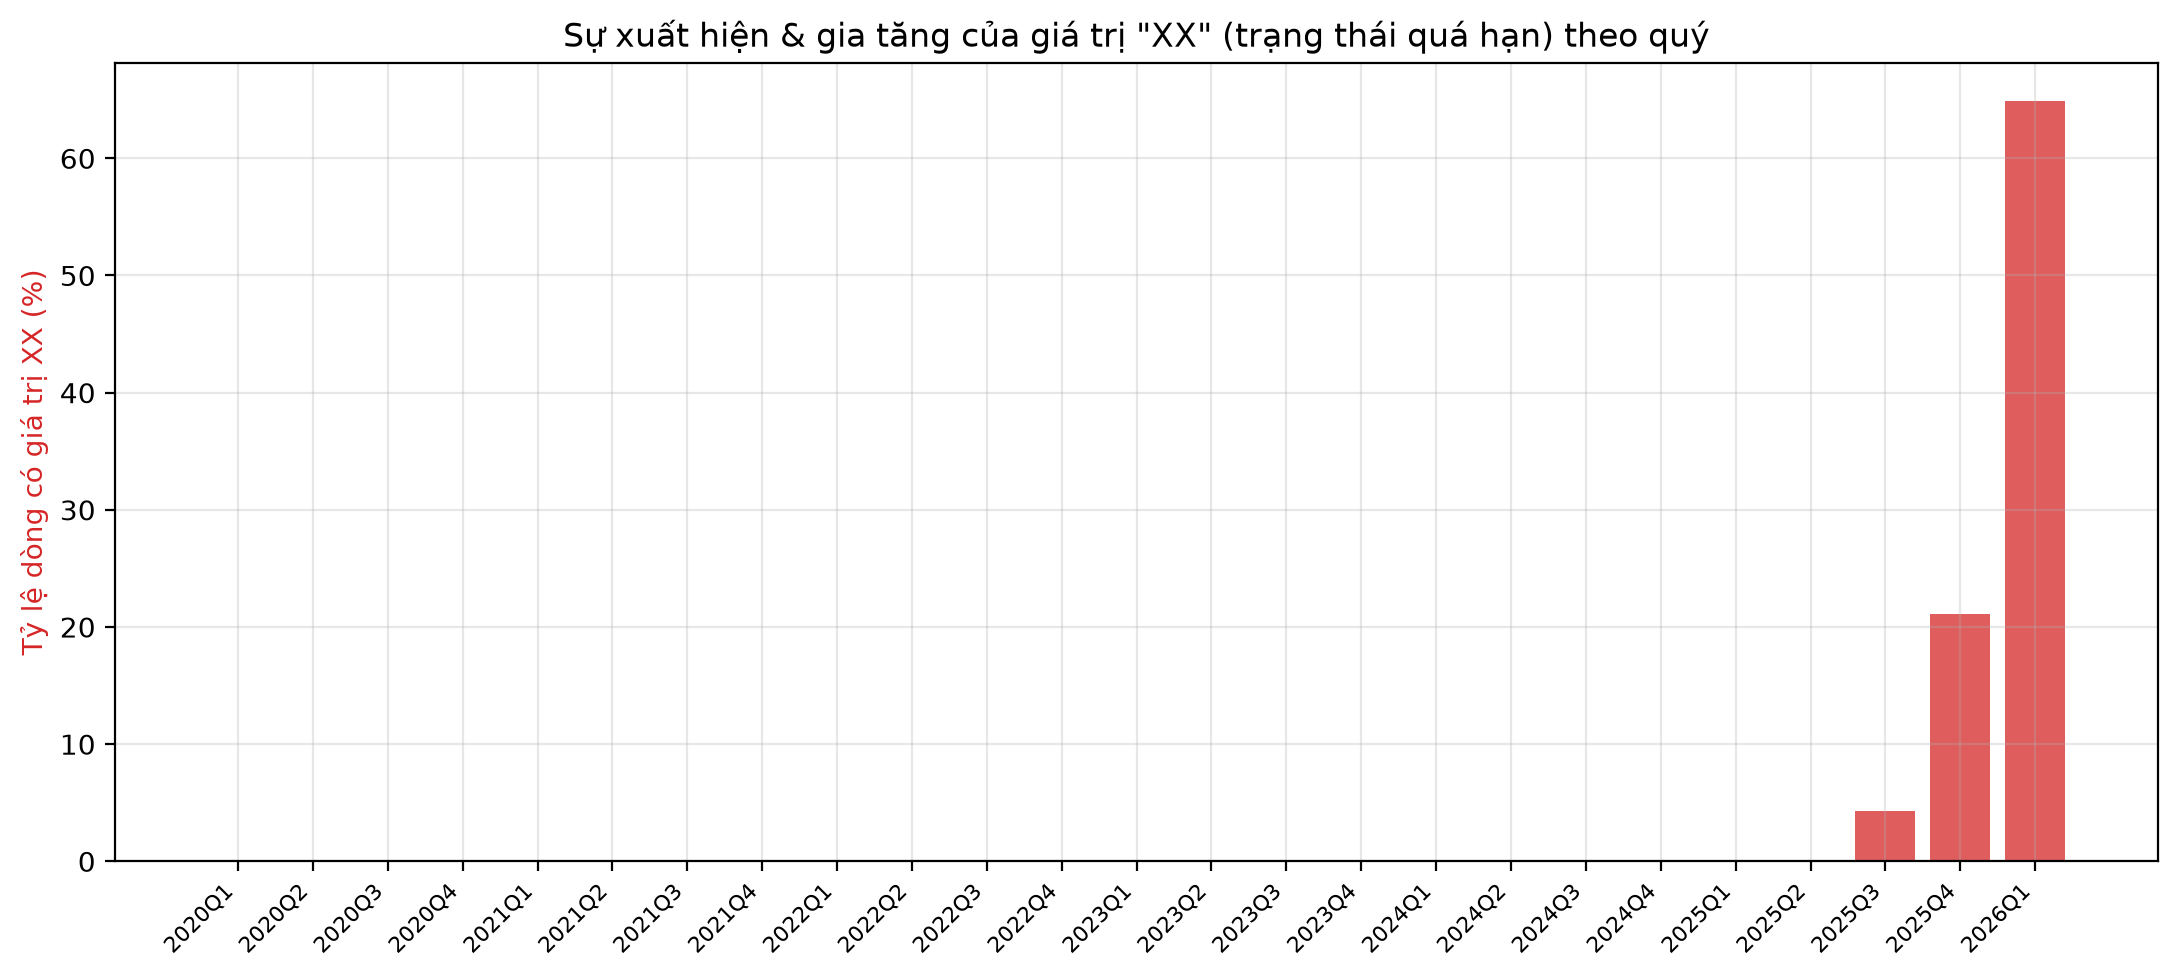

quarter  n_rows  xx_share   n_xx
 2023Q4 4955956    0.0000      0
 2024Q1 4908884    0.0000      0
 2024Q2 5144507    0.0000      0
 2024Q3 5309791    0.0000      0
 2024Q4 4341371    0.0000      0
 2025Q1 2589410    0.0000      0
 2025Q2 2595685    0.0000      0
 2025Q3 1931401    0.0431  83243
 2025Q4 1201439    0.2111 253624
 2026Q1  203412    0.6486 131933


In [6]:
perf = df_m[df_m['source'] == 'perf'].copy().sort_values('quarter').reset_index(drop=True)
# tỷ lệ XX = 1 − validity (cách đọc chặt); validity_spec ≈ 1.0 xác nhận XX là mã hợp lệ theo spec
perf['xx_share'] = (1 - perf['validity']).clip(lower=0)
print('2026Q1 — validity (chặt):', float(perf.loc[perf['quarter']=='2026Q1','validity'].iloc[0]),
      '| validity_spec:', float(perf.loc[perf['quarter']=='2026Q1','validity_spec'].iloc[0]))
df_xx = perf[['quarter', 'n_rows', 'xx_share']].copy()
df_xx['n_xx'] = (df_xx['xx_share'] * df_xx['n_rows']).round().astype('int64')
df_xx.to_csv(dq.OUT_DATA / 'xx_share_by_quarter.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(range(len(df_xx)), df_xx['xx_share'] * 100, color='tab:red', alpha=0.75)
ax.set_xticks(range(len(df_xx)))
ax.set_xticklabels(df_xx['quarter'], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Tỷ lệ dòng có giá trị XX (%)', color='tab:red')
ax.set_title('Sự xuất hiện & gia tăng của giá trị "XX" (trạng thái quá hạn) theo quý')
ax.grid(True, alpha=0.3)
fig.tight_layout()
p = dq.OUT_FIG / 'dq_xx_anomaly.png'
fig.savefig(p, dpi=200, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(p)))
print(df_xx.tail(10).to_string(index=False))


## 4. Phương pháp cải thiện và so sánh trước với sau

Bài dùng hai phương pháp, mỗi phương pháp được đo lại bằng đúng bộ độ đo cũ. Tham số chỉ fit trên Train,
gồm 20 quý đầu từ 2020Q1 đến 2024Q4, theo cách chia 8:1:1 theo trình tự thời gian.

**Thứ nhất, hiệu chỉnh miền giá trị cho validity của file perf.** Quy tắc validity ban đầu dùng miền
`{00..24, RA}`, hẹp hơn miền tài liệu hoá `{00..99, RA, XX}`, nên mọi dòng `XX` bị tính nhầm là vi phạm.
Cách hiệu chỉnh là mở rộng miền đúng theo General User Guide, chặn trên ở 99 và thêm `XX`, đồng thời đồng
bộ quy tắc với từ điển dữ liệu. Sau hiệu chỉnh, `validity` của perf theo cách đọc spec đạt 1.0, còn phần
thiếu được báo cáo đúng bản chất là mất thông tin ở cột trạng thái quá hạn.

**Thứ hai, điền khuyết bằng mode cho completeness của file orig.** Cột `msa` rỗng khoảng 8 đến 13%. Giá trị
điền là mode của `msa` fit chỉ trên 20 quý Train, nhờ đó completeness của cột này đạt 1.0.

Cách làm cũ là median-impute cho `credit_score` và `dti` đã bị bỏ, vì hai cột này không hề rỗng ở bất kỳ
quý nào (đã kiểm chứng 0 null ở mọi quý), nên phép điền không tạo ra thay đổi nào.


  Split 8:1:1 theo quý → Train: 20 quý (2020Q1..2024Q4), Val: 3, Test: 2
  2020Q1: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2020Q2: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2020Q3: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2020Q4: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2021Q1: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2021Q2: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2021Q3: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2021Q4: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2022Q1: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2022Q2: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2022Q3: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2022Q4: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2023Q1: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2023Q2: perf validity (chặt) trước=1.0000 → XX share = 0.00%
  2023Q3: perf validity (chặt) trước=1.0000 →

  Mode msa (fit trên Train): 16984


Đã lưu /home/huynnz/GetAJob/DataMine/output/data/dq_improvement_before_after.csv — 52 dòng

=== Trước / Sau (tổng thể) ===
  scope source    dimension              method   before  after    delta
overall   perf     validity xx_domain_alignment 0.999121    1.0 0.000879
overall   orig completeness msa_mode_imputation 0.907548    1.0 0.092452


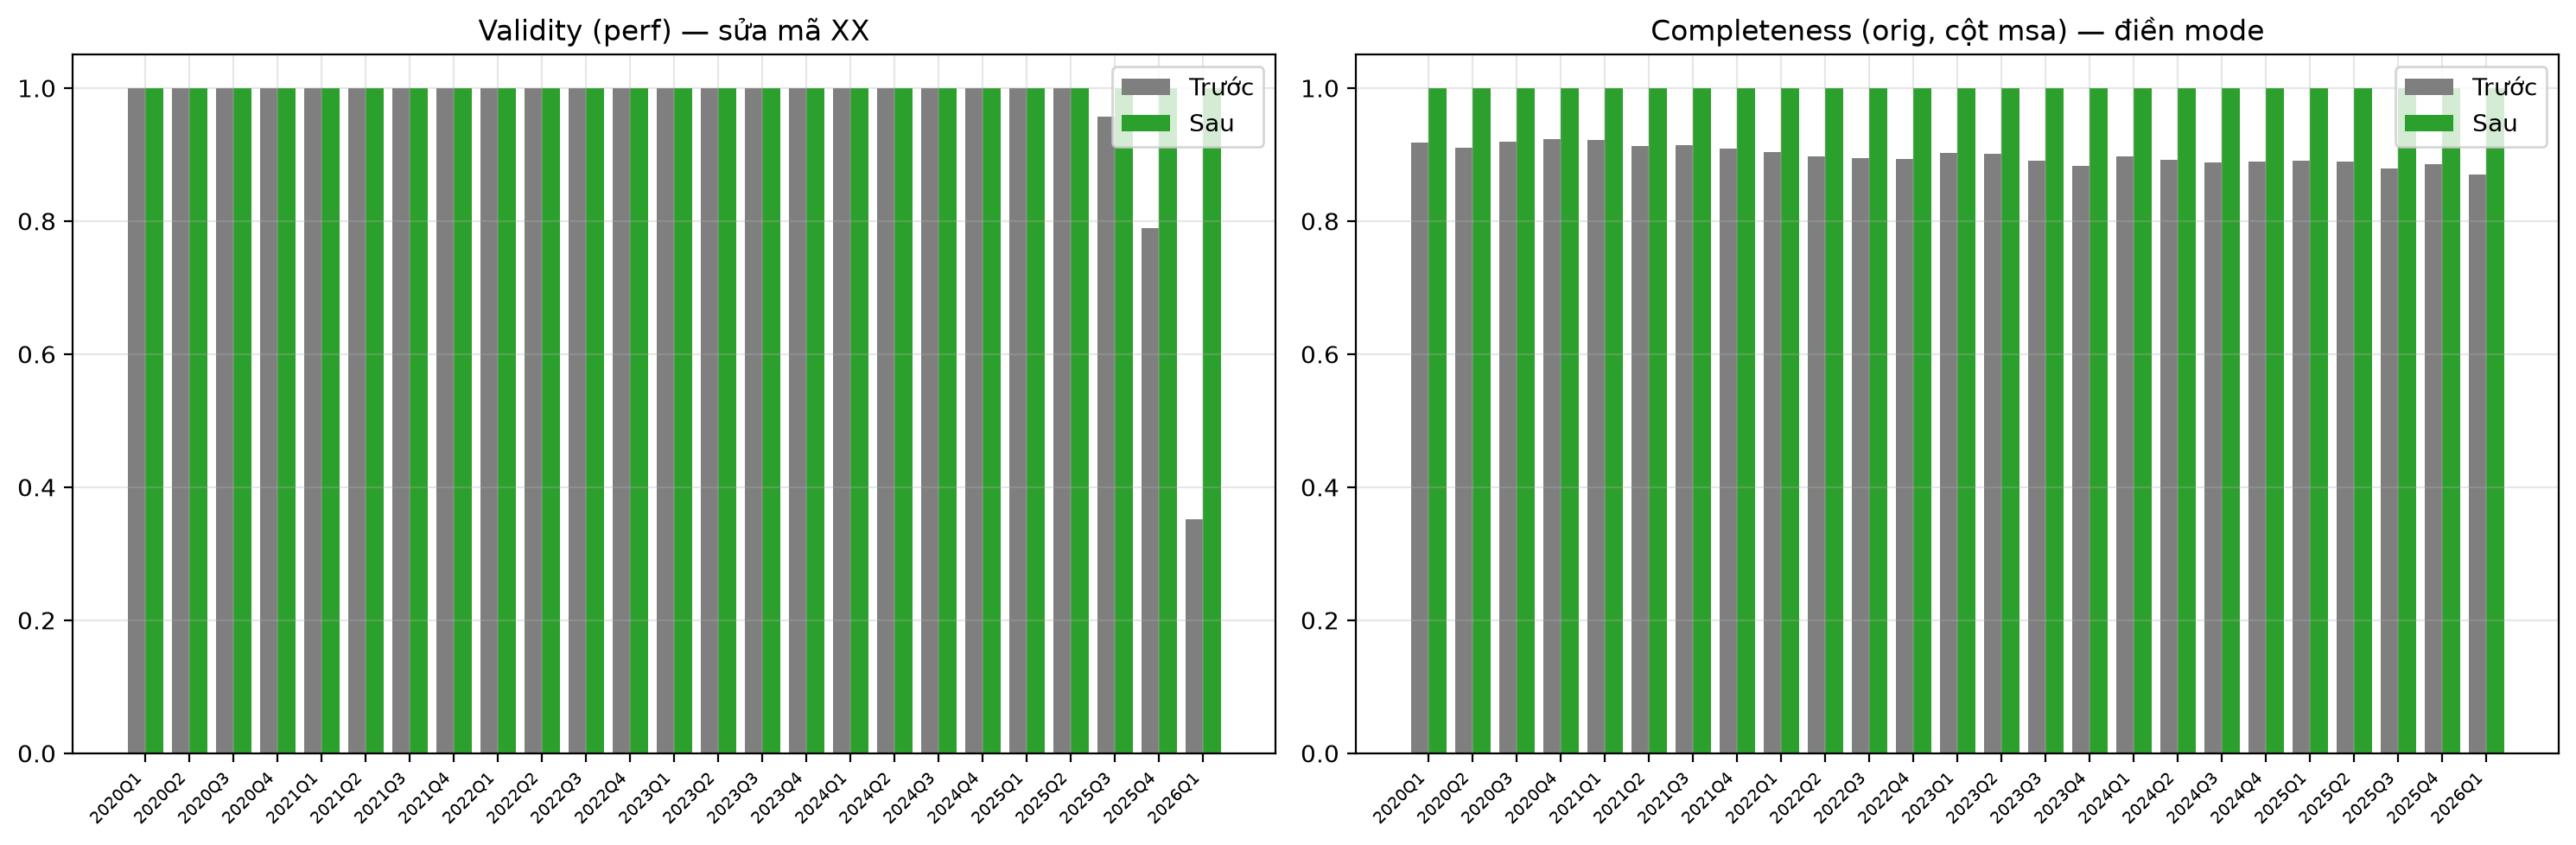

In [7]:
df_i = dq.improvement_before_after(con)
i_path = dq.OUT_DATA / 'dq_improvement_before_after.csv'
df_i.to_csv(i_path, index=False)
print(f"Đã lưu {i_path} — {len(df_i)} dòng\n")

print("=== Trước / Sau (tổng thể) ===")
print(df_i[df_i['scope'] == 'overall'].to_string(index=False))

# Biểu đồ trước/sau theo quý
piv = df_i[df_i['scope'] != 'overall'].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (src, dim, title) in zip(axes, [
        ('perf', 'validity', 'Validity (perf) — sửa mã XX'),
        ('orig', 'completeness', 'Completeness (orig, cột msa) — điền mode')]):
    sub = piv[(piv['source'] == src) & (piv['dimension'] == dim)]
    x = range(len(sub))
    ax.bar([i - 0.2 for i in x], sub['before'], width=0.4, label='Trước', color='tab:gray')
    ax.bar([i + 0.2 for i in x], sub['after'], width=0.4, label='Sau', color='tab:green')
    ax.set_xticks(list(x))
    ax.set_xticklabels(sub['scope'], rotation=45, ha='right', fontsize=7)
    ax.set_ylim(0, 1.05)
    ax.set_title(title)
    ax.legend(); ax.grid(True, alpha=0.3)
fig.tight_layout()
ip = dq.OUT_FIG / 'dq_improvement_chart.png'
fig.savefig(ip, dpi=200, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(ip)))


## Mặt phẳng chẩn đoán (x, y)

Mỗi quan sát, tức một cặp nguồn và quý, được đặt lên mặt phẳng hai chiều để nhận diện kiểu suy giảm của dữ liệu.

Trục hoành là `Ssan+`, đo sức khoẻ dữ liệu, tức mức độ sạch của dữ liệu. Bài dùng proxy minh bạch
`Ssan+ = min(completeness, validity)` theo hướng bảo thủ: một nguồn chỉ được coi là khoẻ khi cả hai khía
cạnh nền tảng đều khoẻ.

Trục tung là `Sperf`, đo hiệu năng dữ liệu, tức mức độ dùng được của dữ liệu. Bài dùng proxy `Sperf` bằng
trung bình sáu khía cạnh đã đo ở mục 2.

Ngưỡng cắt là `x0 = 0.75` và `y0 = 0.70`, tạo ra bốn vùng:

| Vùng | Điều kiện | Hành động đề xuất |
|---|---|---|
| **Bình thường** | x >= x0 và y >= y0 | Theo dõi thường quy |
| **Sức khoẻ thấp** | x < x0 và y >= y0 | Trung bình tạm ổn nhưng có lỗ hổng nền tảng về null hoặc miền giá trị, cần rà soát khía cạnh yếu nhất |
| **Hiệu năng thấp** | x >= x0 và y < y0 | Không có lỗi nghiêm trọng đơn lẻ nhưng tổng thể kém, cần cải thiện lần lượt từng khía cạnh |
| **Nguy hiểm** | x < x0 và y < y0 | Vừa nhiễu vừa kém, cần chặn khỏi tầng BI và xử lý ngay |

Đây vẫn là proxy, đúng ranh giới phạm vi đã ghi ở phần khung lý thuyết. Sperf và Ssan+ chuẩn của AccTEMPO
cần confusion matrix hoặc probability từ mô hình học máy, còn bài cố ý dùng công thức đóng để kiểm chứng được.


Đã lưu mặt phẳng chẩn đoán: /home/huynnz/GetAJob/DataMine/output/data/dq_diagnostic_plane.csv (50 dòng)


Đã lưu biểu đồ: /home/huynnz/GetAJob/DataMine/output/figures/dq_diagnostic_plane.png
Số quan sát (nguồn × quý) theo vùng chẩn đoán:
source  zone         
orig    Bình thường      25
perf    Sức khoẻ thấp    25
dtype: int64

=== Chi tiết kỳ mới nhất: 2026Q1 ===
quarter source    sperf   ssan          zone
 2026Q1   orig 0.988983 0.9343   Bình thường
 2026Q1   perf 0.787817 0.3514 Sức khoẻ thấp

→ Kết luận 2026Q1/perf: Sperf = 0.788 (y; y0 = 0.70), Ssan+ = 0.351 (x; x0 = 0.75) ⇒ vùng: Sức khoẻ thấp


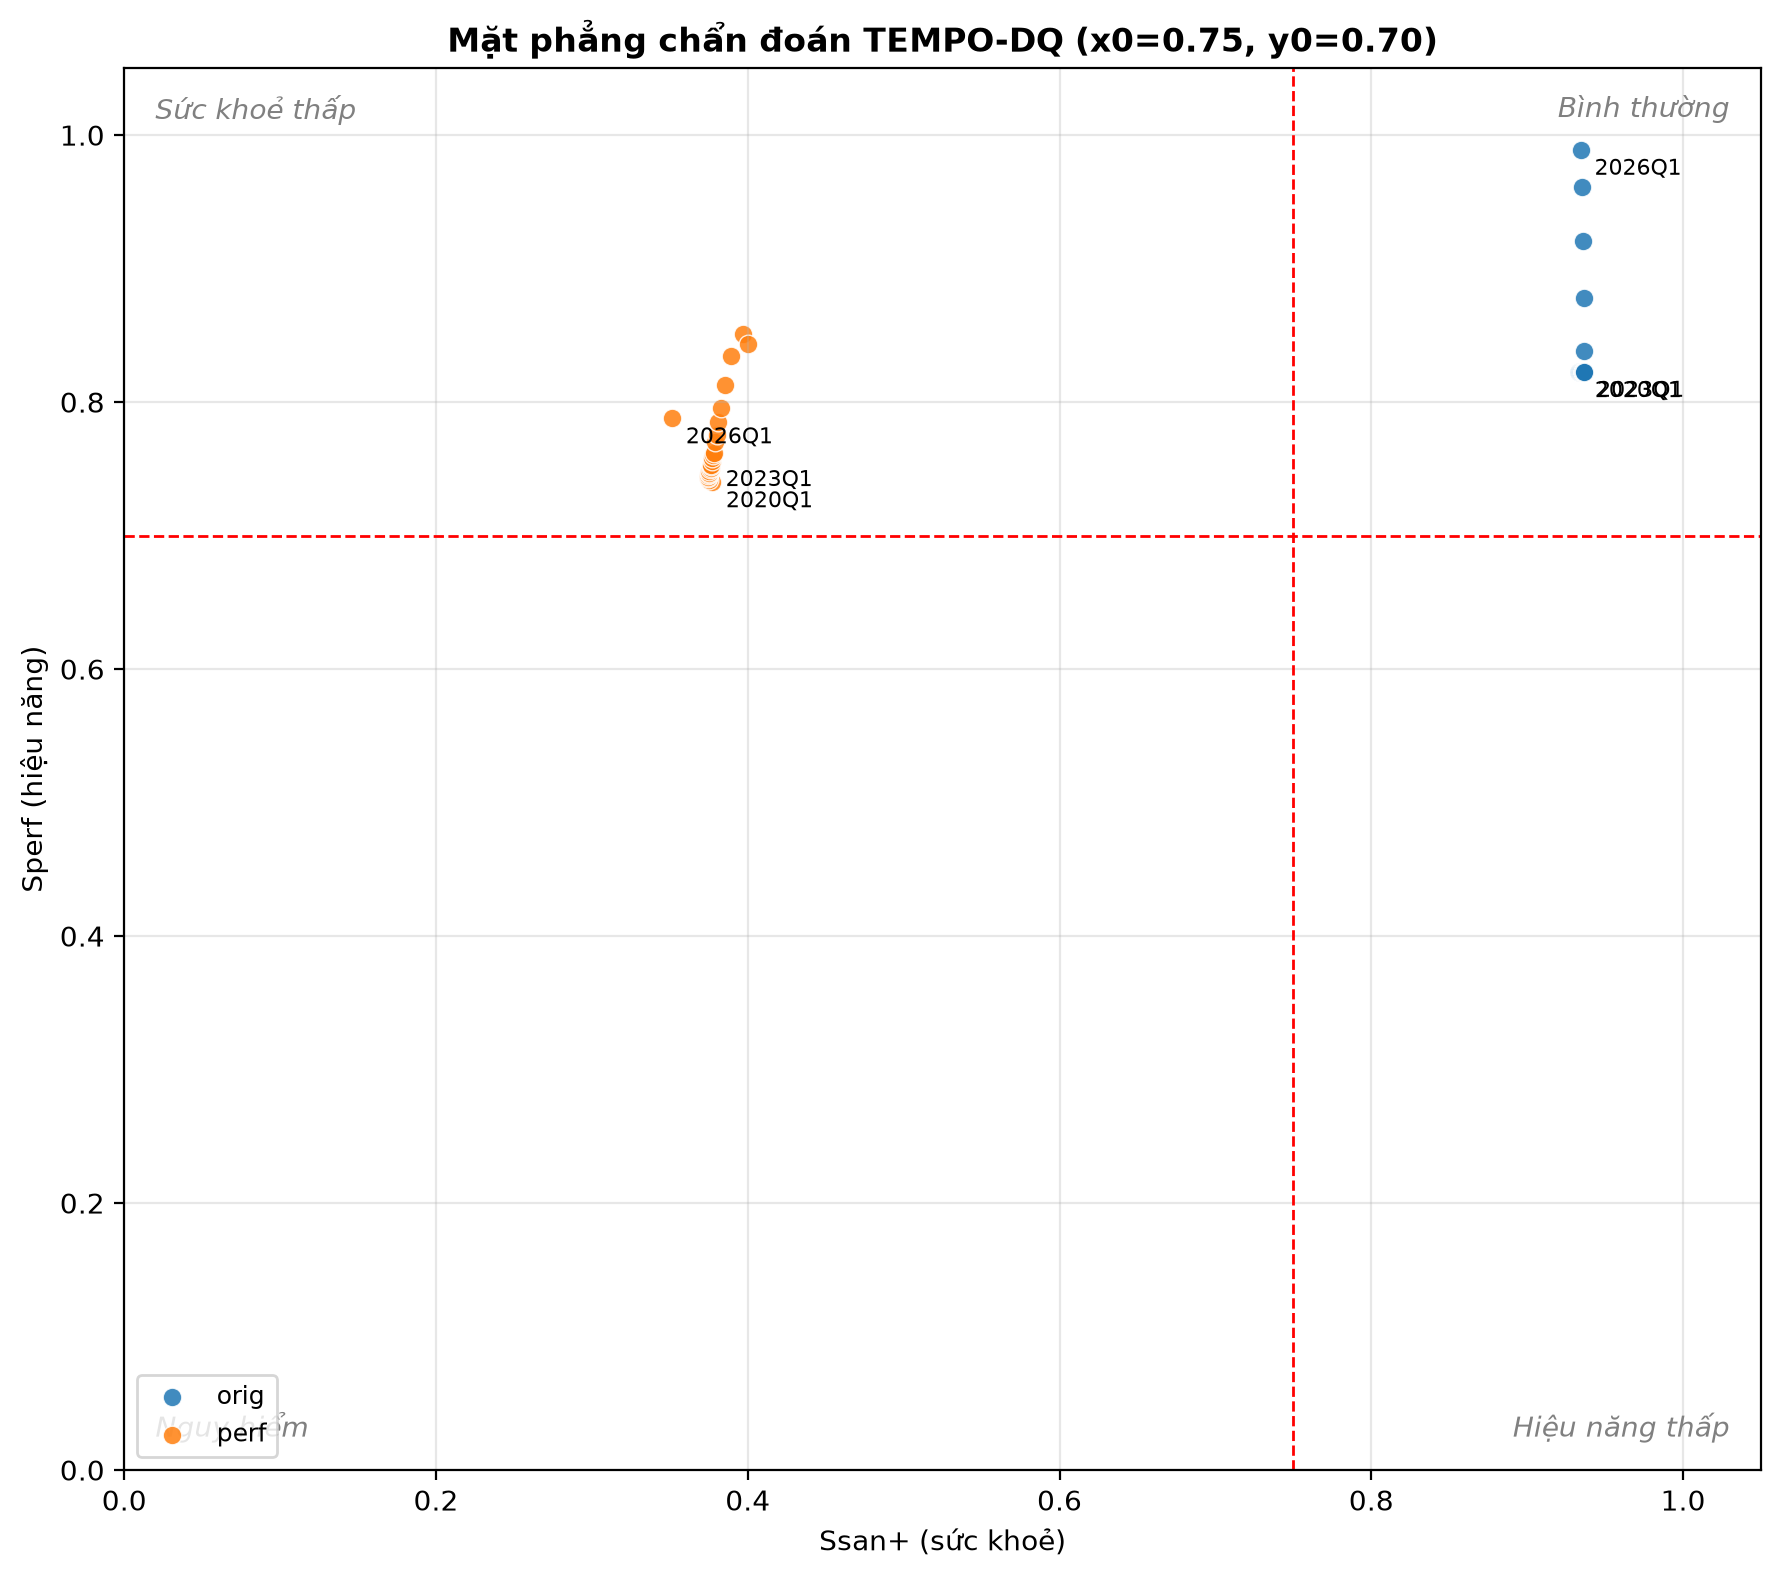

In [8]:
# dq.diagnostic_plane() tự ghi output/data/dq_diagnostic_plane.csv + output/figures/dq_diagnostic_plane.png và trả về DataFrame
# (tái dùng kết nối `con` đã mở ở Mục 2 — kết nối chưa bị đóng)
dp = dq.diagnostic_plane(con)

print("Số quan sát (nguồn × quý) theo vùng chẩn đoán:")
print(dp.groupby(['source', 'zone']).size())

last_q = dp['quarter'].max()
print(f"\n=== Chi tiết kỳ mới nhất: {last_q} ===")
print(dp[dp['quarter'] == last_q].to_string(index=False))

r = dp[(dp['quarter'] == '2026Q1') & (dp['source'] == 'perf')].iloc[0]
print(f"\n→ Kết luận 2026Q1/perf: Sperf = {r['sperf']:.3f} (y; y0 = 0.70), "
      f"Ssan+ = {r['ssan']:.3f} (x; x0 = 0.75) ⇒ vùng: {r['zone']}")

display(Image(filename=str(dq.OUT_FIG / 'dq_diagnostic_plane.png')))


## So sánh với baseline đơn giản

Đề bài yêu cầu luôn so sánh với một baseline đơn giản. Baseline đơn giản nhất và cũng phổ biến nhất trong
thực tế là xoá bản ghi lỗi. Bảng dưới đối chiếu baseline đó với hai phương pháp ở mục 4, tính chỉ từ các
artifact đã lưu là `xx_share_by_quarter.csv` và `dq_improvement_before_after.csv`, không quét lại dữ liệu gốc.


In [9]:
xx = pd.read_csv(dq.OUT_DATA / 'xx_share_by_quarter.csv')
imp = pd.read_csv(dq.OUT_DATA / 'dq_improvement_before_after.csv')

# (1) Validity (perf) — mã XX: baseline = xoá mọi dòng XX → mất đúng xx_share bản ghi
xx_share_all = xx['n_xx'].sum() / xx['n_rows'].sum()      # cả 25 quý, trọng số n_rows
keep_base_xx = 1 - xx_share_all

# (2) Completeness (orig) — cột msa: baseline = xoá mọi dòng msa rỗng
#     before (overall) = completeness của msa = 1 − null_rate → cũng là tỷ lệ giữ lại của baseline
msa = imp[(imp['method'] == 'msa_mode_imputation') & (imp['scope'] == 'overall')].iloc[0]
keep_base_msa = msa['before']

tbl = pd.DataFrame([
    {
        'Cải thiện': 'Validity (perf) — mã "XX"',
        'Baseline': 'Xoá mọi dòng có XX',
        'Metric sau baseline': 1.0,
        'Giữ lại bản ghi baseline': f'{keep_base_xx:.1%}',
        'Phương pháp của ta': 'Đưa XX vào miền hợp lệ (domain alignment, mã đã tài liệu hoá)',
        'Metric sau': 1.0,
        'Giữ lại bản ghi ta': '100%',
        'Kết luận': f'Validity = 1.0 mà không mất dòng nào; baseline mất {xx_share_all:.1%} bản ghi '
                    '(kèm toàn bộ các cột khác của những dòng đó) → ta áp đảo baseline.',
    },
    {
        'Cải thiện': 'Completeness (orig) — cột "msa"',
        'Baseline': 'Xoá mọi dòng có msa rỗng',
        'Metric sau baseline': 1.0,
        'Giữ lại bản ghi baseline': f'{keep_base_msa:.1%}',
        'Phương pháp của ta': 'Điền mode, fit CHỈ trên 20 quý Train',
        'Metric sau': float(msa['after']),
        'Giữ lại bản ghi ta': '100%',
        'Kết luận': f'Completeness = 1.0, giữ 100% bản ghi, không leakage; baseline mất '
                    f'{1 - keep_base_msa:.1%} bản ghi → ta áp đảo baseline.',
    },
])
display(tbl)


,Cải thiện,Baseline,Metric sau baseline,Giữ lại bản ghi baseline,Phương pháp của ta,Metric sau,Giữ lại bản ghi ta,Kết luận
0,"Validity (perf) — mã ""XX""",Xoá mọi dòng có XX,1.0,99.9%,"Đưa XX vào miền hợp lệ (domain alignment, mã đ...",1.0,100%,Validity = 1.0 mà không mất dòng nào; baseline...
1,"Completeness (orig) — cột ""msa""",Xoá mọi dòng có msa rỗng,1.0,90.8%,"Điền mode, fit CHỈ trên 20 quý Train",1.0,100%,"Completeness = 1.0, giữ 100% bản ghi, không le..."


## 5. Đọc trước Chương 5: Phân tích dữ liệu cho doanh nghiệp và kiến trúc BI

Chương 5 định hướng kiến trúc BI theo luồng dữ liệu từ nguồn đến kho dữ liệu hoặc Lakehouse, rồi đến tầng
trình bày gồm dashboard và báo cáo phục vụ ra quyết định. Các mô hình chính gồm:

- Kiến trúc Lakehouse với ba tầng Bronze, Silver và Gold. Bronze chứa dữ liệu thô, Silver chứa dữ liệu đã làm
  sạch và chuẩn hoá, Gold chứa bảng tổng hợp phục vụ BI.
- Hai hướng mô hình hoá kho dữ liệu là Kimball theo hướng chiều và Inmon theo hướng chuẩn hoá.
- ETL hoặc ELT, cùng vai trò của tầng chất lượng dữ liệu. Kết quả sáu khía cạnh trong bài chính là cổng chất
  lượng trước khi dữ liệu vào tầng BI, và dữ liệu không đạt ngưỡng sẽ bị chặn hoặc đánh dấu ở tầng Silver.

Ánh xạ bài này vào các tầng Lakehouse:

| Tầng | Trong bài này |
|---|---|
| **Bronze** | file thô `orig_*.txt` và `perf_*.txt` nạp nguyên trạng, phân tách bằng dấu `|` và chưa kiểm tra |
| **Silver** | dữ liệu sau cổng kiểm tra sáu khía cạnh ở mục 2, gồm miền giá trị, khoá duy nhất và ràng buộc liên trường giữa orig và perf |
| **Gold** | các bảng tổng hợp cho BI gồm `dq_metrics_by_quarter.csv`, `xx_share_by_quarter.csv` và `dq_diagnostic_plane.csv` |

Cơ chế thực thi quy tắc trong Lakehouse hiện đại gồm hai lớp. Delta Lake constraints đặt `NOT NULL` và
`CHECK` trên bảng Silver để chặn giá trị rỗng hoặc ngoài miền ngay lúc ghi. Delta Live Tables expectations
cho phép chọn cách xử lý vi phạm, gồm chỉ ghi nhận, `DROP ROW` để bỏ dòng, hoặc `FAIL UPDATE` để dừng
pipeline. Đây chính là chỗ neo quy tắc chất lượng dữ liệu của bài vào pipeline thật.

Hai tín hiệu trong bài rơi đúng vào hai cơ chế đó. Giá trị `XX` bị expectation kiểu `CHECK` bắt và được xử
lý bằng hiệu chỉnh miền ở tầng Silver, tốt hơn baseline xoá dòng đã bàn ở mục so sánh baseline. Cột `msa`
rỗng bị `NOT NULL` bắt và được xử lý bằng điền mode fit trên Train ở tầng Silver, nên không có null nào bị
đẩy lên Gold.

Khi bàn giao dữ liệu cho BI và ML, bài toán dự báo chia dữ liệu 8:1:1 theo trình tự thời gian, với Train từ
2020Q1 đến 2024Q4. Các quy tắc B1 đến B5 yêu cầu mọi thống kê chỉ được fit trên Train rồi mới áp xuống
Val và Test, gồm điền khuyết bằng mode hoặc median, SMOTE và chuẩn hoá. Đây là việc của tầng bàn giao dữ
liệu từ Gold sang feature store, không phải việc của mô hình. Nếu fit lại trên toàn bộ dữ liệu, kết quả
đánh giá sẽ lạc quan giả tạo.

Kết quả đo chất lượng dữ liệu trong bài, đặc biệt tín hiệu `XX` và mặt phẳng chẩn đoán, là cơ sở để đặt quy
tắc kiểm soát chất lượng tự động trong pipeline BI. Các quy tắc đó gồm ngưỡng cảnh báo theo từng khía cạnh,
giám sát theo thời gian ở mục 3, hành động khắc phục ở mục 4, và quyết định chặn hay nhả dữ liệu ở tầng Silver.

Phần này chỉ tóm tắt nội dung đọc trước cho Chương 5, không thêm phân tích mới.


## 6. Kết luận và sản phẩm

Sản phẩm nằm trong `output/data/` dưới dạng CSV và `output/figures/` dưới dạng PNG.

| # | Nhiệm vụ | Tệp |
|---|---|---|
| 1 | Từ điển dữ liệu và quy tắc | `data/dq_data_dictionary.csv` |
| 2 | Sáu khía cạnh theo quý | `data/dq_metrics_by_quarter.csv` |
| 3 | Trực quan hoá thời gian | `figures/dq_dimensions_timeseries.png` |
| - | Bất thường `XX` | `data/xx_share_by_quarter.csv`, `figures/dq_xx_anomaly.png` |
| 4 | Cải thiện trước và sau | `data/dq_improvement_before_after.csv`, `figures/dq_improvement_chart.png` |
| + | Mặt phẳng chẩn đoán (x, y) | `data/dq_diagnostic_plane.csv`, `figures/dq_diagnostic_plane.png` |
| + | So sánh baseline đơn giản | bảng hiển thị trong notebook, tính từ artifact có sẵn |

Bốn nhiệm vụ của đề đều đã thực hiện, gồm từ điển dữ liệu và quy tắc kiểm tra, sáu khía cạnh ở mức hạt,
trực quan hoá theo thời gian, và phương pháp cải thiện kèm so sánh trước với sau. Bài bổ sung thêm hai phần
nâng cao là mặt phẳng chẩn đoán (x, y) và so sánh với baseline đơn giản.

Các nhận xét chính:

- `uniqueness` và `consistency` xấp xỉ 1.0, cho thấy khoá và liên kết giữa orig và perf đều tốt.
- `timeliness` giảm dần theo độ trễ báo cáo, đúng như thiết kế của độ đo.
- `completeness` của perf thấp vì nhiều cột chỉ có giá trị khi khoản vay kết thúc, chẳng hạn cột
  zero-balance và các cột tổn thất.
- Cột trạng thái quá hạn của perf mất thông tin từ 2023Q3. Giá trị `XX` là Not Available, một mã hợp lệ theo
  spec của Freddie Mac. Cách đọc chặt cho `validity` sụp xuống khoảng 0.35, còn cách đọc theo spec cho
  `validity_spec` xấp xỉ 1.0. Bản chất là mất thông tin, và đây là tín hiệu chất lượng dữ liệu nổi bật nhất
  của bộ dữ liệu.
- Hai phương pháp cải thiện đều vượt baseline xoá dòng. Hiệu chỉnh miền `XX` đưa validity lên 1.0 và giữ lại
  100% bản ghi. Điền mode cho `msa` với tham số fit trên Train đưa completeness lên 1.0, cũng giữ lại 100%
  bản ghi và không gây rò rỉ thời gian.
